In [1]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]
plt.rcParams['font.size'] = 12

In [2]:
import numpy as np 
import json
import os 
import h5py
from qiskit_aer import StatevectorSimulator
from qiskit import transpile, QuantumCircuit

from symmer.operators.base import PauliwordOp, QuantumState

from sympy import var
import h5py
from itertools import combinations

/Users/tom/Documents/ucl/projects/GAS/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
## load data
with h5py.File("H3_data.h5", "r") as infile:

    f_op = PauliwordOp(infile["F_true_symp_matrix"][()],
                       infile["F_true_coeff_vec"][()])

    f_op_rounded = PauliwordOp(infile["F_rounded_symp_matrix"][()],
                                infile["F_rounded_coeff_vec"][()])
    
    linear_true = dict(zip(infile["lin_true_keys"][()],
                       infile["lin_true_values"][()]))
    
    quad_true = dict(zip( [(a,b) for a,b in infile["quad_true_keys"][()]],
                       infile["quad_true_values"][()]))
    

    linear_rounded = dict(zip(infile["lin_rounded_keys"][()],
                    infile["lin_rounded_values"][()]))
    
    quad_rounded   = dict(zip([(a,b) for a,b in infile["quad_rounded_keys"][()]],
                         infile["quad_rounded_values"][()]))
    
    n_elec = infile["SCF_nelec"][()]
    basis_set = infile["SCF_basis"][()]
    n_spin = 2*infile["h1e_MO"][()].shape[0]

print("LOADED")

LOADED


In [4]:
### write QUBO problem!
variables = [var(f'x{q_idx}', bool=True) for q_idx in range(n_spin)]

problem_fn = 0
for q_idx, coeff in linear_rounded.items():
    problem_fn+= variables[q_idx]*coeff

for (q_idx1, q_idx2), coeff in quad_rounded.items():
    problem_fn+= variables[q_idx1]*variables[q_idx2]*coeff

problem_fn

4.0*x0*x1 + 4.0*x0*x2 + 4.0*x0*x3 + 4.0*x0*x4 + 4.0*x0*x5 - 14.0*x0 + 4.0*x1*x2 + 4.0*x1*x3 + 4.0*x1*x4 + 4.0*x1*x5 - 14.0*x1 + 4.0*x2*x3 + 4.0*x2*x4 + 4.0*x2*x5 - 10.0*x2 + 4.0*x3*x4 + 4.0*x3*x5 - 10.0*x3 + 8.0*x4*x5 - 6.0*x4 - 6.0*x5

In [5]:
## go through all valid solutions (classical brute force)

def n_choose_k_vectors(n: int, k: int):
    return np.array(
        [
            [int(i in comb) for i in range(n)]
            for comb in combinations(np.arange(n), k)
        ]
    )

alph_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[0])
beta_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[1])

eigstate_and_vals = dict()
for alpha_term in alph_bitstrings:
    for beta_term in beta_bitstrings:
        state = np.vstack((alpha_term, beta_term)).T.reshape([f_op.n_qubits]) 
        evaluated = int(problem_fn.subs(zip(variables, state)))
        # print(int(evaluated))
        eigstate_and_vals[tuple(state.tolist())] = evaluated
eigstate_and_vals

{(1, 1, 1, 1, 0, 0): -24,
 (1, 1, 1, 0, 0, 1): -20,
 (1, 0, 1, 1, 0, 1): -16,
 (1, 1, 0, 1, 1, 0): -20,
 (1, 1, 0, 0, 1, 1): -12,
 (1, 0, 0, 1, 1, 1): -8,
 (0, 1, 1, 1, 1, 0): -16,
 (0, 1, 1, 0, 1, 1): -8,
 (0, 0, 1, 1, 1, 1): -4}

In [6]:
target_psi = QuantumState(np.array([[0, 0, 1, 1, 1, 1]])) # reverse order due to qiskit ordering

In [7]:
## load output states!
psi_list_nondicke = []
L_list = np.arange(0,9)
with h5py.File("H3_output_non_dicke.h5", "r") as infile2:
    for idx in L_list:
        psi_list_nondicke.append(QuantumState(infile2[f"psi_{idx}_state_matrix"][()],
                                                infile2[f"psi_{idx}_coeff_vec"][()]))


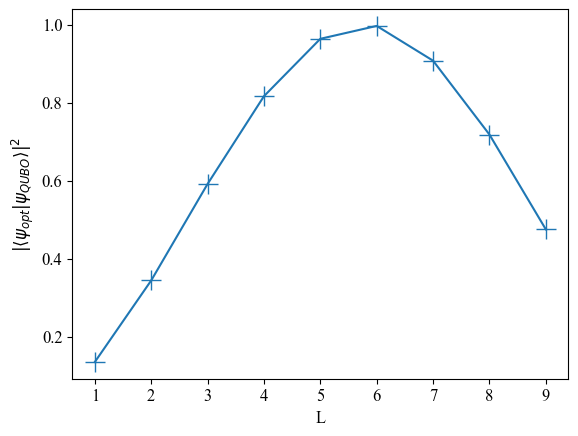

In [8]:
largest_amp_list_nondicke = [np.abs(psi.state_op.coeff_vec[0])**2 for psi in psi_list_nondicke]
largest_bitstring_nondicke = [psi[0] for psi in psi_list_nondicke]
overlap_nondicke = [np.abs(target_psi.dagger * psi)**2 for psi in psi_list_nondicke]

plt.plot(L_list+1, overlap_nondicke, marker="+", markersize=15)
plt.xlabel("L")
plt.ylabel(r"$|\langle \psi_{opt}| \psi_{QUBO} \rangle|^{2}$")
plt.savefig('H3_nondicke_L.png', dpi=300)
plt.show()

In [9]:
### shows largest ampltidue state with increasing L
largest_bitstring_nondicke

[ 0.367+0.000j |001111>,
  0.586+0.000j |001111>,
  0.769+0.000j |001111>,
  0.904+0.000j |001111>,
  0.982+0.000j |001111>,
  0.998+0.000j |001111>,
  0.953+0.000j |001111>,
  0.847+0.000j |001111>,
  0.689+0.000j |001111>]

In [10]:
psi_list_dicke = []
with h5py.File("H3_output_dicke.h5", "r") as infile3:
    for idx in L_list:
        psi_list_dicke.append(QuantumState(infile3[f"psi_{idx}_state_matrix"][()],
                                            infile3[f"psi_{idx}_coeff_vec"][()]))

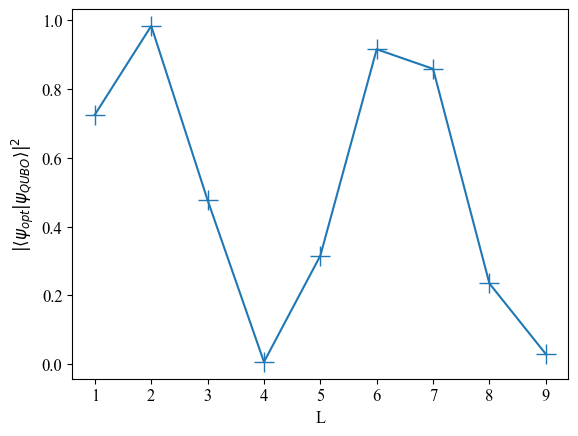

In [11]:
largest_amp_list_dicke = [np.abs(psi.state_op.coeff_vec[0])**2 for psi in psi_list_dicke]
largest_bitstring_dicke = [psi[0] for psi in psi_list_dicke]
overlap_dicke = [np.abs(target_psi.dagger * psi)**2 for psi in psi_list_dicke]

plt.plot(L_list+1, overlap_dicke, marker="+", markersize=15)
plt.xlabel("L")
plt.ylabel(r"$|\langle \psi_{opt}| \psi_{QUBO} \rangle|^{2}$")
plt.savefig('H3_dicke_L.png', dpi=300)
plt.show()

In [12]:
largest_bitstring_dicke

[ 0.852+0.000j |001111>,
  0.992+0.000j |001111>,
  0.691+0.000j |001111>,
  0.352+0.000j |111100>,
  0.562+0.000j |001111>,
  0.957+0.000j |001111>,
  0.927+0.000j |001111>,
  0.485+0.000j |001111>,
  0.348+0.000j |111100>]